# Ottawa EV Charging Usage — Data Acquisition and Cleaning

This notebook prepares the City of Ottawa electric-vehicle charging usage dataset for exploratory analysis and visualization.

### Cleaning objectives
- Retrieve all available records from the ArcGIS Feature Server.
- Standardize column names and remove redundant technical fields.
- Validate the multiple date/time fields supplied in the source data.
- Build reliable session start/end timestamps and derived time features.
- Investigate duration and energy anomalies rather than removing records blindly.
- Standardize addresses for reliable grouping and mapping.
- Perform final data-quality checks and save analysis-ready files.

**Starting dataset:** 22,455 charging-session records and 27 source columns.


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import MarkerCluster
import geopandas as gpd
import pandas as pd
from pyproj import Transformer

plt.rcParams["figure.figsize"] = (20, 7)

import requests

## 1. Fetch Data from the ArcGIS Feature Server

The ArcGIS service limits the number of records returned in a single request.  
The function below therefore retrieves the dataset in batches of 1,000 records, combines the attribute and geometry information, and saves the full result locally as a CSV file.


In [2]:
def fetch_arcgis_data(base_url):
    all_features = []
    offset = 0
    record_count = 1000  # Default batch size for ArcGIS queries

    print("Fetching data from ArcGIS Feature Server...")

    while True:
        params = {
            "where": "1=1",  # Retrieve all records
            "outFields": "*",  # Select all attributes
            "f": "json",  # Request format
            "resultOffset": offset,
            "resultRecordCount": record_count,
            "returnGeometry": "true",  # Include spatial coordinates if available
        }

        response = requests.get(base_url, params=params)

        if response.status_code != 200:
            print(f"Error fetching data: HTTP {response.status_code}")
            break

        data = response.json()

        # Check if features are returned
        features = data.get("features", [])
        if not features:
            break

        # Flatten features (combining attributes and geometry coordinates)
        for f in features:
            row = f.get("attributes", {})
            geometry = f.get("geometry", {})
            if geometry:
                row["x"] = geometry.get("x")
                row["y"] = geometry.get("y")
            all_features.append(row)

        print(f"Retrieved {len(all_features)} records so far...")

        # If fewer records returned than requested, we've reached the end
        if len(features) < record_count:
            break

        offset += record_count

    df = pd.DataFrame(all_features)
    print(
        f"Done! Downloaded a total of {len(df)} records with {len(df.columns)} columns."
    )
    return df


# Dataset URL provided
url = "https://services.arcgis.com/G6F8XLCl5KtAlZ2G/arcgis/rest/services/Electric_Vehicle_Charging_Stations_Usage_Data/FeatureServer/0/query"

# Execute fetch and save locally
df = fetch_arcgis_data(url)
df.to_csv("ev_charging_usage.csv", index=False)

Fetching data from ArcGIS Feature Server...
Retrieved 1000 records so far...
Retrieved 2000 records so far...
Retrieved 3000 records so far...
Retrieved 4000 records so far...
Retrieved 5000 records so far...
Retrieved 6000 records so far...
Retrieved 7000 records so far...
Retrieved 8000 records so far...
Retrieved 9000 records so far...
Retrieved 10000 records so far...
Retrieved 11000 records so far...
Retrieved 12000 records so far...
Retrieved 13000 records so far...
Retrieved 14000 records so far...
Retrieved 15000 records so far...
Retrieved 16000 records so far...
Retrieved 17000 records so far...
Retrieved 18000 records so far...
Retrieved 19000 records so far...
Retrieved 20000 records so far...
Retrieved 21000 records so far...
Retrieved 22000 records so far...
Retrieved 22455 records so far...
Done! Downloaded a total of 22455 records with 27 columns.


## 2. Initial Data Inspection

Before cleaning, inspect the dataset dimensions, column names, data types, and null counts.  
This establishes the original structure and helps identify redundant or unusable fields.


In [3]:
df.shape

(22455, 27)

In [4]:
df.columns

Index(['X', 'Y', 'Transaction_ID', 'Session_ID', 'Session_start_date',
       'Session_end_date', 'Connect_Start_Date', 'Connect_Start_Time',
       'F24_Hour_Start_Time_Format', 'Connect_End_Date', 'Connect_End_Time',
       'F24_Hour_Connect_End_Time', 'Charging_Time', 'Province_or_state',
       'Owner', 'Site', 'Address', 'POINT_X', 'POINT_Y', 'Station',
       'Card_number', 'ObjectId', 'End_Reason', 'Total_kWh', 'ObjectId2', 'x',
       'y'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22455 entries, 0 to 22454
Data columns (total 27 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   X                           22455 non-null  float64
 1   Y                           22455 non-null  float64
 2   Transaction_ID              22455 non-null  int64  
 3   Session_ID                  22455 non-null  object 
 4   Session_start_date          22455 non-null  object 
 5   Session_end_date            22455 non-null  object 
 6   Connect_Start_Date          22455 non-null  object 
 7   Connect_Start_Time          22455 non-null  object 
 8   F24_Hour_Start_Time_Format  22455 non-null  object 
 9   Connect_End_Date            22455 non-null  object 
 10  Connect_End_Time            22455 non-null  object 
 11  F24_Hour_Connect_End_Time   22455 non-null  object 
 12  Charging_Time               22455 non-null  object 
 13  Province_or_state           224

## 3. Standardize the Schema

Column names are converted to lowercase for consistency.

The ArcGIS response contains several redundant technical fields. The original `x`/`y` fields and the geometry-derived `x`/`y` fields are removed because `point_x` and `point_y` are retained as the primary spatial coordinates.

`objectid` is empty, while `objectid2` is an ArcGIS record identifier that is not required for the analysis.


In [6]:
# 1. Standardize column names to lowercase
df.columns = df.columns.str.strip().str.lower()

# 2. Drop completely empty / useless ID columns and redundant duplicate coordinates
# Keeping 'point_x' and 'point_y' as our primary spatial coordinate set
cols_to_drop = ["objectid", "objectid2", "x", "y"]
df = df.drop(
    columns=[col for col in cols_to_drop if col in df.columns], errors="ignore"
)
df.columns

Index(['transaction_id', 'session_id', 'session_start_date',
       'session_end_date', 'connect_start_date', 'connect_start_time',
       'f24_hour_start_time_format', 'connect_end_date', 'connect_end_time',
       'f24_hour_connect_end_time', 'charging_time', 'province_or_state',
       'owner', 'site', 'address', 'point_x', 'point_y', 'station',
       'card_number', 'end_reason', 'total_kwh'],
      dtype='object')

In [7]:
# Confirm there are no duplicate column names
df.columns.duplicated().sum()

0

In [8]:
df.shape

(22455, 21)

## 4. Validate Date and Time Fields

The source contains several overlapping representations of session and connection timestamps.

Rather than dropping these fields immediately, the values are compared first to determine which timestamps are most reliable. This is important because small source-data inconsistencies were discovered during validation.


In [9]:
# Check the current date/time formats
date_time_cols = [
    "session_start_date",
    "session_end_date",
    "connect_start_date",
    "connect_start_time",
    "f24_hour_start_time_format",
    "connect_end_date",
    "connect_end_time",
    "f24_hour_connect_end_time"
]

df[date_time_cols].head(10)

,session_start_date,session_end_date,connect_start_date,connect_start_time,f24_hour_start_time_format,connect_end_date,connect_end_time,f24_hour_connect_end_time
0,5/1/2022 11:36:44 AM,5/1/2022 12:10:32 PM,5/1/2022,11:36:44 AM,11:36:44,5/1/2022,12:10:32 PM,12:10:32
1,5/1/2022 12:07:03 PM,5/1/2022 12:57:10 PM,5/1/2022,12:07:03 PM,12:07:03,5/1/2022,12:57:10 PM,12:57:10
2,5/1/2022 11:43:33 AM,5/1/2022 2:40:34 PM,5/1/2022,11:43:33 AM,11:43:33,5/1/2022,2:40:34 PM,14:40:34
3,5/1/2022 1:21:37 PM,5/1/2022 2:57:49 PM,5/1/2022,1:21:37 PM,13:21:37,5/1/2022,2:57:49 PM,14:57:49
4,5/1/2022 3:00:19 PM,5/1/2022 3:35:18 PM,5/1/2022,3:00:19 PM,15:00:19,5/1/2022,3:35:18 PM,15:35:18
5,5/1/2022 1:51:18 PM,5/1/2022 4:41:30 PM,5/1/2022,1:51:18 PM,13:51:18,5/1/2022,4:41:30 PM,16:41:30
6,5/1/2022 4:45:14 PM,5/1/2022 6:30:41 PM,5/1/2022,4:45:14 PM,16:45:14,5/1/2022,6:30:41 PM,18:30:41
7,5/1/2022 6:34:25 PM,5/1/2022 8:07:26 PM,5/1/2022,6:34:25 PM,18:34:25,5/1/2022,8:07:26 PM,20:07:26
8,5/2/2022 2:32:58 PM,5/2/2022 3:08:40 PM,5/2/2022,2:32:58 PM,14:32:58,5/2/2022,3:08:40 PM,15:08:40
9,5/2/2022 1:31:40 PM,5/2/2022 3:14:33 PM,5/2/2022,1:31:40 PM,13:31:40,5/2/2022,3:14:33 PM,15:14:33


In [10]:
# Display the first row vertically for the selected date/time columns
df[date_time_cols].iloc[0]

session_start_date            5/1/2022 11:36:44 AM
session_end_date              5/1/2022 12:10:32 PM
connect_start_date                        5/1/2022
connect_start_time                     11:36:44 AM
f24_hour_start_time_format                11:36:44
connect_end_date                          5/1/2022
connect_end_time                       12:10:32 PM
f24_hour_connect_end_time                 12:10:32
Name: 0, dtype: object

In [11]:
# Compare session start/end with connection start/end
df[
    [
        "session_start_date",
        "connect_start_date",
        "connect_start_time",
        "session_end_date",
        "connect_end_date",
        "connect_end_time"
    ]
].head(10)

,session_start_date,connect_start_date,connect_start_time,session_end_date,connect_end_date,connect_end_time
0,5/1/2022 11:36:44 AM,5/1/2022,11:36:44 AM,5/1/2022 12:10:32 PM,5/1/2022,12:10:32 PM
1,5/1/2022 12:07:03 PM,5/1/2022,12:07:03 PM,5/1/2022 12:57:10 PM,5/1/2022,12:57:10 PM
2,5/1/2022 11:43:33 AM,5/1/2022,11:43:33 AM,5/1/2022 2:40:34 PM,5/1/2022,2:40:34 PM
3,5/1/2022 1:21:37 PM,5/1/2022,1:21:37 PM,5/1/2022 2:57:49 PM,5/1/2022,2:57:49 PM
4,5/1/2022 3:00:19 PM,5/1/2022,3:00:19 PM,5/1/2022 3:35:18 PM,5/1/2022,3:35:18 PM
5,5/1/2022 1:51:18 PM,5/1/2022,1:51:18 PM,5/1/2022 4:41:30 PM,5/1/2022,4:41:30 PM
6,5/1/2022 4:45:14 PM,5/1/2022,4:45:14 PM,5/1/2022 6:30:41 PM,5/1/2022,6:30:41 PM
7,5/1/2022 6:34:25 PM,5/1/2022,6:34:25 PM,5/1/2022 8:07:26 PM,5/1/2022,8:07:26 PM
8,5/2/2022 2:32:58 PM,5/2/2022,2:32:58 PM,5/2/2022 3:08:40 PM,5/2/2022,3:08:40 PM
9,5/2/2022 1:31:40 PM,5/2/2022,1:31:40 PM,5/2/2022 3:14:33 PM,5/2/2022,3:14:33 PM


### 4.1 Compare Full Session Timestamps with Fragmented Connection Timestamps

`session_start_date` and `session_end_date` contain complete date-time values.

For validation, separate connection date and time fields are recombined and compared with the full session timestamps across all records.

**Finding:** all reconstructed start timestamps matched the full session start timestamps, while 53 reconstructed end timestamps did not.


In [12]:
# Convert full session timestamps to datetime
df["session_start_date"] = pd.to_datetime(df["session_start_date"])
df["session_end_date"] = pd.to_datetime(df["session_end_date"])

# Rebuild connection timestamps from separate date + time columns
connect_start_dt = pd.to_datetime(
    df["connect_start_date"] + " " + df["connect_start_time"]
)

connect_end_dt = pd.to_datetime(
    df["connect_end_date"] + " " + df["connect_end_time"]
)

# Compare across all rows
print(
    "Start timestamps match:",
    (df["session_start_date"] == connect_start_dt).all()
)

print(
    "End timestamps match:",
    (df["session_end_date"] == connect_end_dt).all()
)

Start timestamps match: True
End timestamps match: False


### 4.2 Investigate the 53 End-Timestamp Mismatches

The mismatches were inspected rather than automatically corrected.

The time-of-day values matched, but the separate `connect_end_date` field was typically one calendar month behind the full `session_end_date` at month boundaries. This indicates a source-data rollover issue in the fragmented end-date field rather than a genuine difference in session timing.


In [13]:
# Count rows where session end does not match connect end
end_mismatch = df["session_end_date"] != connect_end_dt

print("End timestamp mismatches:", end_mismatch.sum())

End timestamp mismatches: 53


In [14]:
# Inspect mismatched end timestamps
df.loc[
    end_mismatch,
    [
        "session_end_date",
        "connect_end_date",
        "connect_end_time",
        "charging_time",
        "end_reason"
    ]
].head(20)

,session_end_date,connect_end_date,connect_end_time,charging_time,end_reason
1128,2022-07-01 01:41:20,6/1/2022,1:41:20 AM,2:16:07,The charging cable was disconnected and put ba...
1727,2022-06-01 03:48:06,5/1/2022,3:48:06 AM,5:19:23,Stopped by operator
1729,2022-06-01 11:47:29,5/1/2022,11:47:29 AM,17:58:09,Charging ended by vehicle
2338,2022-09-01 02:33:20,8/1/2022,2:33:20 AM,7:13:20,Charging ended by vehicle
2340,2022-09-01 08:18:28,8/1/2022,8:18:28 AM,10:29:01,Charging ended by vehicle
2832,2022-08-01 06:08:32,7/1/2022,6:08:32 AM,7:35:43,Charging ended by vehicle
2833,2022-08-01 08:28:23,7/1/2022,8:28:23 AM,9:09:29,The charging cable was disconnected and put ba...
4605,2022-11-01 06:28:54,10/1/2022,6:28:54 AM,9:16:02,The charging cable was disconnected and put ba...
4971,2022-12-01 05:18:04,11/1/2022,5:18:04 AM,7:08:08,Charging ended by vehicle
4972,2022-12-01 08:00:08,11/1/2022,8:00:08 AM,9:27:48,Charging ended by vehicle


In [15]:
# Check the date difference for mismatched records
date_check = pd.DataFrame({
    "session_end": df.loc[end_mismatch, "session_end_date"],
    "connect_end": connect_end_dt.loc[end_mismatch]
})

# Calculate the difference in days
date_check["difference"] = (
    date_check["session_end"] - date_check["connect_end"]
)

date_check.head(20)

,session_end,connect_end,difference
1128,2022-07-01 01:41:20,2022-06-01 01:41:20,30 days
1727,2022-06-01 03:48:06,2022-05-01 03:48:06,31 days
1729,2022-06-01 11:47:29,2022-05-01 11:47:29,31 days
2338,2022-09-01 02:33:20,2022-08-01 02:33:20,31 days
2340,2022-09-01 08:18:28,2022-08-01 08:18:28,31 days
2832,2022-08-01 06:08:32,2022-07-01 06:08:32,31 days
2833,2022-08-01 08:28:23,2022-07-01 08:28:23,31 days
4605,2022-11-01 06:28:54,2022-10-01 06:28:54,31 days
4971,2022-12-01 05:18:04,2022-11-01 05:18:04,30 days
4972,2022-12-01 08:00:08,2022-11-01 08:00:08,30 days


### 4.3 Validate the Reported Charging Duration

The source `charging_time` field is converted to a timedelta and compared with the duration calculated directly from the full session timestamps.

**Finding:** 22,445 of 22,455 records matched exactly. The remaining 10 differed by exactly 24 hours.

Those 10 sessions lasted longer than one day, indicating that the source `charging_time` field wraps after 24 hours. Therefore, duration calculated from the full session timestamps is used as the analytical duration measure.


In [16]:
# Convert charging_time to a timedelta
df["charging_time_td"] = pd.to_timedelta(df["charging_time"])

# Calculate duration from the session timestamps
df["session_duration"] = (
    df["session_end_date"] - df["session_start_date"]
)

# Compare the two
duration_match = df["session_duration"] == df["charging_time_td"]

print("Duration matches:", duration_match.sum())
print("Duration mismatches:", (~duration_match).sum())

Duration matches: 22445
Duration mismatches: 10


In [17]:
df.loc[
    end_mismatch,
    [
        "session_start_date",
        "session_end_date",
        "charging_time",
        "session_duration",
        "end_reason"
    ]
].head(20)

,session_start_date,session_end_date,charging_time,session_duration,end_reason
1128,2022-06-30 23:25:13,2022-07-01 01:41:20,2:16:07,0 days 02:16:07,The charging cable was disconnected and put ba...
1727,2022-05-31 22:28:43,2022-06-01 03:48:06,5:19:23,0 days 05:19:23,Stopped by operator
1729,2022-05-31 17:49:20,2022-06-01 11:47:29,17:58:09,0 days 17:58:09,Charging ended by vehicle
2338,2022-08-31 19:20:00,2022-09-01 02:33:20,7:13:20,0 days 07:13:20,Charging ended by vehicle
2340,2022-08-31 21:49:27,2022-09-01 08:18:28,10:29:01,0 days 10:29:01,Charging ended by vehicle
2832,2022-07-31 22:32:49,2022-08-01 06:08:32,7:35:43,0 days 07:35:43,Charging ended by vehicle
2833,2022-07-31 23:18:54,2022-08-01 08:28:23,9:09:29,0 days 09:09:29,The charging cable was disconnected and put ba...
4605,2022-10-31 21:12:52,2022-11-01 06:28:54,9:16:02,0 days 09:16:02,The charging cable was disconnected and put ba...
4971,2022-11-30 22:09:56,2022-12-01 05:18:04,7:08:08,0 days 07:08:08,Charging ended by vehicle
4972,2022-11-30 22:32:20,2022-12-01 08:00:08,9:27:48,0 days 09:27:48,Charging ended by vehicle


In [18]:
# Check whether the duration mismatches overlap with the bad end-date records
print(
    "Duration mismatches within end-date mismatches:",
    ((~duration_match) & end_mismatch).sum()
)

Duration mismatches within end-date mismatches: 1


In [19]:
# Inspect the 10 sessions where calculated duration differs from charging_time
df.loc[
    ~duration_match,
    [
        "session_start_date",
        "session_end_date",
        "charging_time",
        "session_duration",
        "end_reason",
        "total_kwh"
    ]
]

,session_start_date,session_end_date,charging_time,session_duration,end_reason,total_kwh
9075,2023-06-18 21:18:37,2023-06-20 02:44:00,5:25:23,1 days 05:25:23,Charging ended by vehicle,11.35067
9320,2023-06-23 16:13:34,2023-06-25 11:02:28,18:48:54,1 days 18:48:54,Charging ended by vehicle,44.59517
9507,2023-07-13 12:29:22,2023-07-14 13:39:03,1:09:41,1 days 01:09:41,The charging cable was disconnected and put ba...,29.60633
11051,2023-09-01 17:31:02,2023-09-02 20:46:14,3:15:12,1 days 03:15:12,Charging ended by vehicle,58.22506
15127,2023-12-24 13:06:37,2023-12-25 15:33:58,2:27:21,1 days 02:27:21,Charging ended by vehicle,64.61534
15518,2023-12-31 14:02:54,2024-01-01 18:13:00,4:10:06,1 days 04:10:06,Charging ended by vehicle,57.58440
17088,2024-03-04 14:26:26,2024-03-05 16:41:28,2:15:02,1 days 02:15:02,The charging cable was disconnected and put ba...,29.08895
20495,2024-05-23 10:22:03,2024-05-24 10:51:17,0:29:14,1 days 00:29:14,Charging ended by vehicle,69.38225
20528,2024-05-18 09:17:03,2024-05-19 18:36:50,9:19:47,1 days 09:19:47,Charging ended by vehicle,41.76706
20675,2024-05-16 17:12:21,2024-05-18 10:04:34,16:52:13,1 days 16:52:13,Charging ended by vehicle,58.18813


In [20]:
# Calculate the difference between the timestamp duration
# and the supplied charging_time
df.loc[~duration_match, "duration_difference"] = (
    df.loc[~duration_match, "session_duration"]
    - df.loc[~duration_match, "charging_time_td"]
)

# Check the unique differences
df.loc[~duration_match, "duration_difference"].value_counts()

duration_difference
1 days    10
Name: count, dtype: int64

## 5. Create Reliable Session Timestamps and Time Features

Because the full session timestamps proved more reliable than the fragmented connection fields, they are retained as the canonical start and end values.

New analytical features are then created:
- `duration_hours` — full elapsed session duration in hours
- `start_hour` — hour of day when the session began
- `day_of_week` — weekday name
- `month_year` — monthly period for trend analysis

The redundant fragmented date/time columns are then removed.


In [21]:
# Create clean unified datetime columns from the reliable full timestamps
df["session_start"] = pd.to_datetime(
    df["session_start_date"],
    errors="coerce"
)

df["session_end"] = pd.to_datetime(
    df["session_end_date"],
    errors="coerce")

In [22]:
# Drop original fragmented / redundant date-time columns
fragmented_time_cols = [
    "session_start_date",
    "session_end_date",
    "connect_start_date",
    "connect_start_time",
    "f24_hour_start_time_format",
    "connect_end_date",
    "connect_end_time",
    "f24_hour_connect_end_time",
]

df = df.drop(
    columns=fragmented_time_cols,
    errors="ignore"
)

In [23]:
# Extract useful time-based features
df["duration_hours"] = (
    df["session_end"] - df["session_start"]
).dt.total_seconds() / 3600

df["start_hour"] = df["session_start"].dt.hour

df["day_of_week"] = df["session_start"].dt.day_name()

df["month_year"] = df["session_start"].dt.to_period("M")

In [24]:
# Display updated schema summary
print(f"Cleaned shape: {df.shape}")

print("\nRemaining columns:")
print(df.dtypes)

Cleaned shape: (22455, 22)

Remaining columns:
transaction_id                   int64
session_id                      object
charging_time                   object
province_or_state               object
owner                           object
site                            object
address                         object
point_x                        float64
point_y                        float64
station                         object
card_number                     object
end_reason                      object
total_kwh                      float64
charging_time_td       timedelta64[ns]
session_duration       timedelta64[ns]
duration_difference    timedelta64[ns]
session_start           datetime64[ns]
session_end             datetime64[ns]
duration_hours                 float64
start_hour                       int32
day_of_week                     object
month_year                   period[M]
dtype: object


### 5.1 Remove Temporary Validation Fields

The temporary timedelta columns were useful for diagnosing the source-data issues but are not required for the final analytical dataset.


In [25]:
# Drop temporary validation columns used during cleaning
validation_cols = [
    "charging_time_td",
    "session_duration",
    "duration_difference",
]

df = df.drop(columns=validation_cols, errors="ignore")

# Check final shape and schema
print(df.shape)

(22455, 19)


In [26]:
df.head()

,transaction_id,session_id,charging_time,province_or_state,owner,site,address,point_x,point_y,station,card_number,end_reason,total_kwh,session_start,session_end,duration_hours,start_hour,day_of_week,month_year
0,8971546,ce499016-c0fe-4b76-9224-e8e9e8b1caa3,0:33:48,ON,City of Ottawa,City of Ottawa - 190 Richmond Road,190 Richmond Rd.,-75.7475,45.39466,AAA-14533,1.10E+12,Charging ended by vehicle,4.06440,2022-05-01 11:36:44,2022-05-01 12:10:32,0.563333,11,Sunday,2022-05
1,8971910,daeaa8b8-2528-4b2a-a1ea-4aab820f188f,0:50:07,ON,City of Ottawa,City of Ottawa - 245 Crichton St.,245 Crichton St.,-75.6823,45.43930,AAA-14506,1.10E+12,The charging cable was disconnected and put ba...,2.92454,2022-05-01 12:07:03,2022-05-01 12:57:10,0.835278,12,Sunday,2022-05
2,8972766,5e4d5163-2c67-4049-ac1d-41193e6064d9,2:57:01,ON,City of Ottawa,City of Ottawa - 186 Main St.,186 Main St.,-75.6782,45.40886,AAA-14503,RC01086626836246,Charging ended by vehicle,20.59820,2022-05-01 11:43:33,2022-05-01 14:40:34,2.950278,11,Sunday,2022-05
3,8972887,c83802a2-1f6d-4c24-bba2-5bff14371aec,1:36:12,ON,City of Ottawa,City of Ottawa - 301 Laurier Avenue,301 Laurier Ave. E,-75.6793,45.42710,AAA-14508,MA01090921821958,The charging cable was disconnected and put ba...,11.52725,2022-05-01 13:21:37,2022-05-01 14:57:49,1.603333,13,Sunday,2022-05
4,8973165,24715a5e-ccee-420f-ac17-0414a5ec14aa,0:34:59,ON,City of Ottawa,City of Ottawa - 2nd Avenue Parking Garage,170 Second Ave.,-75.6893,45.40323,AAB-20483,RC01086626807904,The charging cable was disconnected and put ba...,3.17881,2022-05-01 15:00:19,2022-05-01 15:35:18,0.583056,15,Sunday,2022-05


## 6. Validate Duration and Energy Values

Session duration and energy consumption are reviewed for impossible, zero, or extreme values.

No negative session durations were found. Long-duration sessions were retained because their timestamps, energy consumption, and end reasons were plausible.


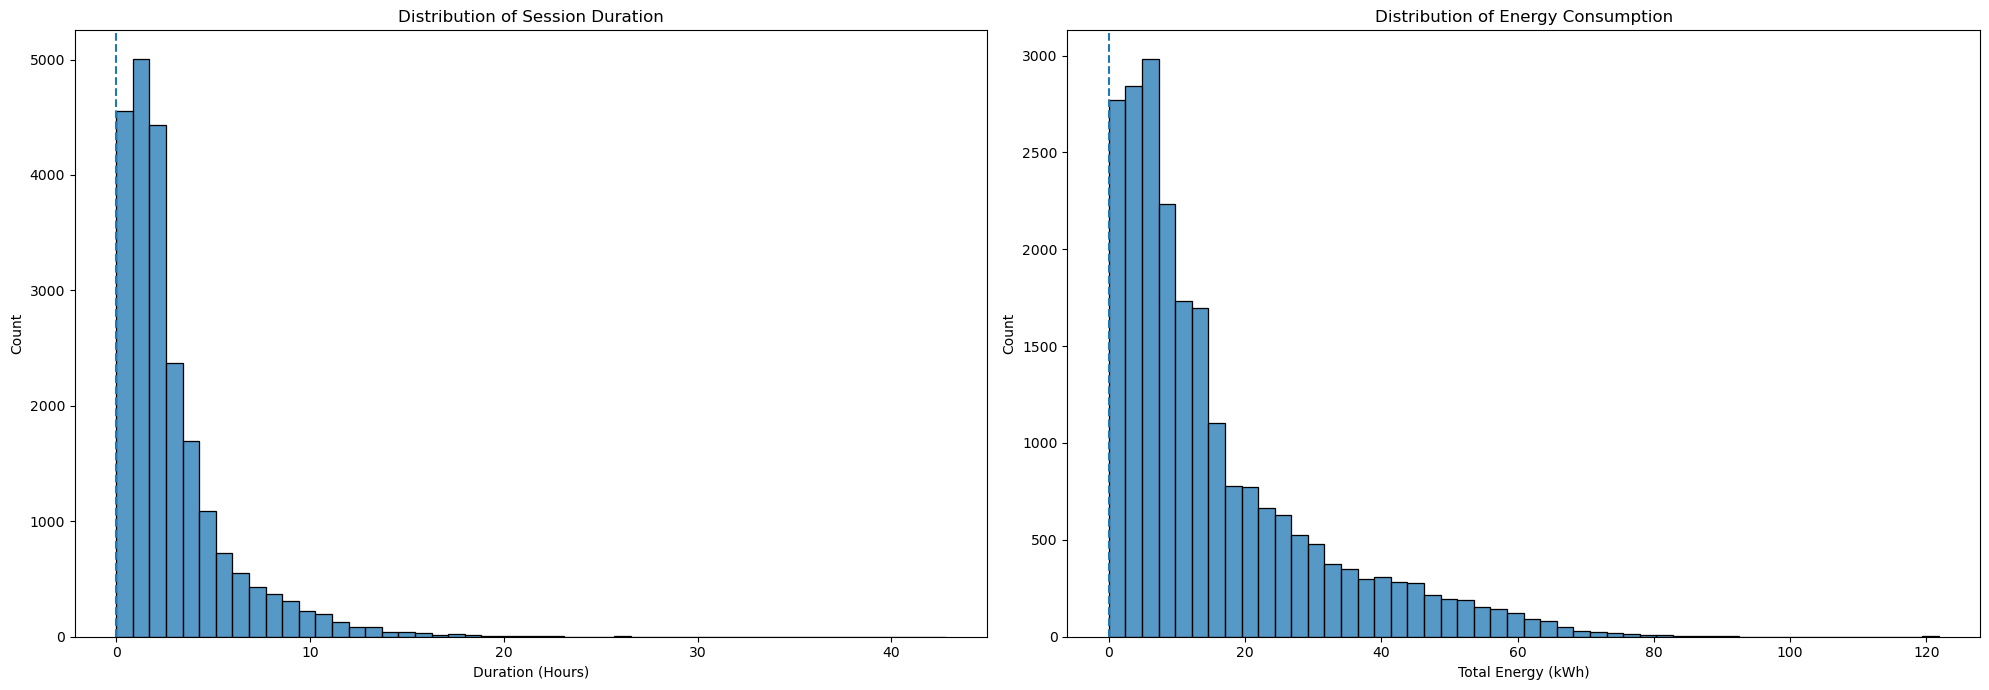

In [27]:
# Create side-by-side validation plots
fig, axes = plt.subplots(1, 2)

# Session duration distribution
sns.histplot(
    df["duration_hours"],
    bins=50,
    ax=axes[0]
)

# Mark zero so negative values would appear to the left
axes[0].axvline(0, linestyle="--")
axes[0].set_title("Distribution of Session Duration")
axes[0].set_xlabel("Duration (Hours)")
axes[0].set_ylabel("Count")

# Energy consumption distribution
sns.histplot(
    df["total_kwh"],
    bins=50,
    ax=axes[1]
)

# Mark zero so negative values would appear to the left
axes[1].axvline(0, linestyle="--")
axes[1].set_title("Distribution of Energy Consumption")
axes[1].set_xlabel("Total Energy (kWh)")
axes[1].set_ylabel("Count")

# Prevent labels from overlapping
plt.tight_layout()

plt.show()

In [28]:
# Check for negative session durations
negative_duration_count = (df["duration_hours"] < 0).sum()

print("Negative duration_hours:", negative_duration_count)

Negative duration_hours: 0


In [29]:
print(df[["total_kwh", "duration_hours"]].describe())

          total_kwh  duration_hours
count  22455.000000    22455.000000
mean      15.573271        2.862517
std       15.165360        2.882785
min        0.000000        0.000000
25%        4.870825        1.033611
50%       10.276760        1.997222
75%       21.649070        3.641667
max      121.781100       42.815000


### 6.1 Zero-Energy and Zero-Duration Sessions

Zero-energy sessions are retained because they may represent legitimate failed, interrupted, or non-charging connection attempts and may be useful for later operational analysis.

Six records had zero session duration. These provide no meaningful elapsed-time information and were removed from the analytical dataset.

**Rows after removal:** 22,449.


In [30]:
#Check for zero or negative consumption/duration sessions
zero_kwh_count = (df["total_kwh"] <= 0).sum()
negative_duration_count = (df["duration_hours"] <= 0).sum()

print(f"\nSessions with total_kwh <= 0: {zero_kwh_count}")
print(f"Sessions with duration_hours <= 0: {negative_duration_count}")


Sessions with total_kwh <= 0: 289
Sessions with duration_hours <= 0: 6


In [31]:
# Inspect longest charging sessions
df.nlargest(
    10,
    "duration_hours"
)[
    [
        "session_start",
        "session_end",
        "duration_hours",
        "total_kwh",
        "end_reason",
        "site",
        "station",
    ]
]

,session_start,session_end,duration_hours,total_kwh,end_reason,site,station
9320,2023-06-23 16:13:34,2023-06-25 11:02:28,42.815000,44.59517,Charging ended by vehicle,City of Ottawa - 118 Cartier St.,AAA-14499
20675,2024-05-16 17:12:21,2024-05-18 10:04:34,40.870278,58.18813,Charging ended by vehicle,City of Ottawa - 301 Laurier Avenue,AAA-14508
20528,2024-05-18 09:17:03,2024-05-19 18:36:50,33.329722,41.76706,Charging ended by vehicle,City of Ottawa - 186 Main St.,AAA-14503
9075,2023-06-18 21:18:37,2023-06-20 02:44:00,29.423056,11.35067,Charging ended by vehicle,City of Ottawa - 122 Daly Ave.,AAA-14516
15518,2023-12-31 14:02:54,2024-01-01 18:13:00,28.168333,57.58440,Charging ended by vehicle,City of Ottawa - 118 Cartier St.,AAA-14499
11051,2023-09-01 17:31:02,2023-09-02 20:46:14,27.253333,58.22506,Charging ended by vehicle,City of Ottawa - 6 Oak St.,AAA-14521
15127,2023-12-24 13:06:37,2023-12-25 15:33:58,26.455833,64.61534,Charging ended by vehicle,City of Ottawa - Chapel Hill Park N Ride,AAB-20388
17088,2024-03-04 14:26:26,2024-03-05 16:41:28,26.250556,29.08895,The charging cable was disconnected and put ba...,City of Ottawa - 190 Richmond Road,AAA-14535
9507,2023-07-13 12:29:22,2023-07-14 13:39:03,25.161389,29.60633,The charging cable was disconnected and put ba...,City of Ottawa - 190 Richmond Road,AAA-14535
20495,2024-05-23 10:22:03,2024-05-24 10:51:17,24.487222,69.38225,Charging ended by vehicle,City of Ottawa - Chapel Hill Park N Ride,AAB-20388


In [32]:
# Inspect sessions with zero or negative energy consumption
df.loc[
    df["total_kwh"] <= 0,
    [
        "session_start",
        "session_end",
        "duration_hours",
        "total_kwh",
        "end_reason",
        "site",
        "station",
    ]
].head(20)

,session_start,session_end,duration_hours,total_kwh,end_reason,site,station
23,2022-05-04 15:22:39,2022-05-04 15:22:55,0.004444,0.0,The charging cable was disconnected and put ba...,City of Ottawa - 118 Cartier St.,AAA-14499
26,2022-05-04 18:10:53,2022-05-04 18:12:51,0.032778,0.0,Charging ended by vehicle,City of Ottawa - 2nd Avenue Parking Garage,AAB-20483
34,2022-05-05 09:16:42,2022-05-05 09:16:54,0.003333,0.0,The charging cable was disconnected and put ba...,City of Ottawa - 118 Cartier St.,AAA-14499
224,2022-05-18 18:14:39,2022-05-18 18:18:35,0.065556,0.0,Charging ended by vehicle,City of Ottawa - 170 Primrose Ave.,AAA-14497
247,2022-05-20 20:47:16,2022-05-20 20:50:18,0.050556,0.0,Charging ended by vehicle,City of Ottawa - 170 Primrose Ave.,AAA-14497
248,2022-05-20 20:51:13,2022-05-20 20:53:27,0.037222,0.0,Charging ended by vehicle,City of Ottawa - 170 Primrose Ave.,AAA-14497
283,2022-05-22 10:58:50,2022-05-22 11:00:11,0.022500,0.0,Charging ended by vehicle,City of Ottawa - 170 Primrose Ave.,AAA-14497
284,2022-05-22 11:00:38,2022-05-22 11:01:17,0.010833,0.0,The charging cable was disconnected and put ba...,City of Ottawa - 170 Primrose Ave.,AAA-14497
296,2022-05-22 13:53:52,2022-05-22 14:25:06,0.520556,0.0,Charging ended by vehicle,City of Ottawa - 170 Primrose Ave.,AAA-14497
543,2022-05-23 14:44:04,2022-05-23 14:46:14,0.036111,0.0,Charging ended by vehicle,City of Ottawa - 6 Oak St.,AAA-14521


In [33]:
# Inspect zero-duration sessions
df.loc[
    df["duration_hours"] <= 0,
    [
        "session_start",
        "session_end",
        "duration_hours",
        "total_kwh",
        "end_reason",
        "site",
        "station",
    ]
]

,session_start,session_end,duration_hours,total_kwh,end_reason,site,station
1264,2022-06-22 11:21:06,2022-06-22 11:21:06,0.0,0.00000,Unknown reason,City of Ottawa - 113 Beechwood Ave.,AAA-14514
1577,2022-07-12 12:21:55,2022-07-12 12:21:55,0.0,0.00005,Unknown reason,City of Ottawa - 186 Main St.,AAA-14503
1598,2022-07-13 14:49:49,2022-07-13 14:49:49,0.0,0.00000,Unknown reason,City of Ottawa - 930 Wellington Street,AAA-14501
3277,2022-10-22 11:10:15,2022-10-22 11:10:15,0.0,0.00000,Unknown reason,City of Ottawa - 190 Richmond Road,AAA-14535
6369,2023-03-11 15:53:32,2023-03-11 15:53:32,0.0,0.00000,Stopped by operator,City of Ottawa - 2nd Avenue Parking Garage,AAB-20483
22420,2024-06-23 17:15:42,2024-06-23 17:15:42,0.0,0.00000,Stopped by operator,City of Ottawa - Chapel Hill Park N Ride,AAB-20388


In [34]:
# Remove zero-duration sessions
df = df[df["duration_hours"] > 0].copy()

# Verify
print("Remaining rows:", len(df))
print("Zero-duration sessions:", (df["duration_hours"] <= 0).sum())

Remaining rows: 22449
Zero-duration sessions: 0


## 7. Final Data-Quality Validation

The cleaned dataset is checked for:
- missing values
- fully duplicated rows
- duplicate transaction IDs
- duplicate session IDs
- plausible coordinate ranges
- province/state consistency

The final validation showed no missing values or duplicate identifiers, and all records belong to Ontario.


In [35]:
# Final validation checks

# 1. Missing values
print(df.isna().sum().sort_values(ascending=False))

# 2. Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 3. Duplicate transaction IDs
print("Duplicate transaction IDs:", df["transaction_id"].duplicated().sum())

# 4. Duplicate session IDs
print("Duplicate session IDs:", df["session_id"].duplicated().sum())

# 5. Check coordinates
print(df[["point_x", "point_y"]].describe())

# 6. Check categorical consistency
print(df["province_or_state"].value_counts())

transaction_id       0
card_number          0
day_of_week          0
start_hour           0
duration_hours       0
session_end          0
session_start        0
total_kwh            0
end_reason           0
station              0
session_id           0
point_y              0
point_x              0
address              0
site                 0
owner                0
province_or_state    0
charging_time        0
month_year           0
dtype: int64
Duplicate rows: 0
Duplicate transaction IDs: 0
Duplicate session IDs: 0
            point_x       point_y
count  22449.000000  22449.000000
mean     -75.682785     45.417985
std        0.047097      0.012343
min      -75.747500     45.394660
25%      -75.690300     45.408860
50%      -75.686400     45.416010
75%      -75.679300     45.427100
max      -75.488000     45.441660
province_or_state
ON    22449
Name: count, dtype: int64


## 8. Standardize Addresses

Address formatting differences can cause the same physical location to appear as multiple categories during grouping.

Periods, leading/trailing spaces, and repeated internal spaces are removed to create `address_clean`.

This reduced the number of unique addresses from 19 to 18. For example, formatting variants of the City Hall address were consolidated into one standardized value.


In [36]:
# Create a standardized address field
df["address_clean"] = (
    df["address"]
    .str.replace(".", "", regex=False)
    .str.strip()
)

In [37]:
# Standardize repeated spaces
df["address_clean"] = (
    df["address_clean"]
    .str.replace(r"\s+", " ", regex=True)
)

In [38]:
# Compare unique address counts before and after cleaning
print("Original unique addresses:", df["address"].nunique())
print("Cleaned unique addresses:", df["address_clean"].nunique())

Original unique addresses: 19
Cleaned unique addresses: 18


In [39]:
df.loc[
    df["site"].str.contains("City Hall", case=False, na=False),
    ["site", "address", "address_clean", "station"]
].drop_duplicates()

,site,address,address_clean,station
6,City Hall - Ottawa,110 Laurier Ave. W,110 Laurier Ave W,AAB-15265
900,City Hall - Ottawa,110 Laurier Ave W.,110 Laurier Ave W,AAB-15265


### 8.1 Check Addresses Associated with Multiple Site Names

After address standardization, each cleaned address is checked against the number of associated site labels.

`40 Cobourg St` correctly maps to two separate site labels — **North** and **South** — with distinct station IDs. This is a legitimate operational distinction and is therefore retained.


In [40]:
df.groupby("address_clean")["site"].nunique().sort_values(ascending=False)

address_clean
40 Cobourg St        2
110 Laurier Ave W    1
113 Beechwood Ave    1
6 Oak St             1
33 Quill St          1
301 Laurier Ave E    1
2925 Navan Rd        1
283 Cyr Ave          1
245 Crichton St      1
200 Glen Park Dr     1
190 Richmond Rd      1
186 Main St          1
170 Second Ave       1
170 Primrose Ave     1
1551 Lycee Place     1
122 Daly Ave         1
118 Cartier St       1
930 Wellington St    1
Name: site, dtype: int64

In [41]:
# Inspect the address linked to multiple site names
df.loc[
    df["address_clean"] == "40 Cobourg St",
    ["site", "address", "address_clean", "station", "point_x", "point_y"]
].drop_duplicates()

,site,address,address_clean,station,point_x,point_y
12011,City of Ottawa - 40 Cobourg St - North,40 Cobourg St,40 Cobourg St,AAB-21717,-75.6815,45.43427
12037,City of Ottawa - 40 Cobourg St - North,40 Cobourg St,40 Cobourg St,AAB-21730,-75.6815,45.43427
12106,City of Ottawa - 40 Cobourg St - South,40 Cobourg St,40 Cobourg St,AAB-21710,-75.6815,45.43427
12142,City of Ottawa - 40 Cobourg St - South,40 Cobourg St,40 Cobourg St,AAB-21718,-75.6815,45.43427


## 9. Save the Cleaned Dataset

The final analysis-ready dataset contains **22,449 charging sessions**.

Two output formats are saved:
- **CSV** for portability and easy inspection
- **Parquet** for analysis because it preserves data types such as datetime values more reliably

The Parquet file is the preferred input for the separate analysis notebook.


In [42]:
# Save cleaned dataset for analysis notebook
df.to_csv("ev_charging_usage_cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [43]:
# Save a Parquet copy to preserve datatypes
df.to_parquet("ev_charging_usage_cleaned.parquet", index=False)

print("Parquet dataset saved successfully.")

"""Using Parquet means you should get session_start, session_end, and the other datatypes back without having to reconvert them."""

Parquet dataset saved successfully.


'Using Parquet means you should get session_start, session_end, and the other datatypes back without having to reconvert them.'

---

## Cleaning Summary

The cleaning process preserved valid operational records while correcting for known source-data limitations.

Key outcomes:
- 22,455 original sessions reduced to **22,449 usable sessions**
- redundant ArcGIS technical fields removed
- full session timestamps selected as the authoritative date/time source
- 53 fragmented end-date rollover inconsistencies identified
- 10 source `charging_time` values identified as wrapping after 24 hours
- zero-duration sessions removed
- zero-kWh sessions retained for possible operational/failure analysis
- addresses standardized for reliable site grouping and mapping
- no missing values or duplicate transaction/session IDs remained after cleaning

The dataset is now ready for exploratory analysis, visualization, station-utilization analysis, and mapping.
